In [1]:
# Initialization, styling configuration, and helper utilities
%matplotlib inline

import math

import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from ipywidgets import interact, widgets

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import foundations as hp

hp.setup_theme()

# Useful Functions in Machine Learning & Deep Learning

- Neural networks transform inputs through layers of linear combinations, the **pre-activations** $a$, followed by nonlinear functions. Most of these act element-wise, on one pre-activation at a time; softmax maps a whole vector $\mathbf{a}$ to a vector.
- In machine learning and deep learning, nonlinear functions fulfill two fundamentally distinct architectural roles:
  1. **Hidden-unit activations $h(a)$**: introduce nonlinearity, so that multilayer networks compute flexible representations and do not collapse into a single linear model.
  2. **Output-unit activations $f(a)$**: map pre-activations to the domain of the target distribution (probabilities in $(0, 1)$, categorical distributions on the probability simplex, strictly positive scales $\sigma^2 > 0$). In statistics, the inverse $f^{-1}$ is called the **link function**.
- This lecture is the reference catalogue of these functions; later lectures build on it *(→ Lecture 05_classification, 06_deep_networks, 08_backpropagation)*.

> 💡 **Key Takeaway:** The mathematical and optimization properties of activation functions—differentiability, gradient magnitude, monotonicity, and saturation—fundamentally dictate how efficiently deep models train and generalize.

## Historical Foundations: Threshold & Step Functions

- **Problem:** a neuron has to turn its **pre-activation** $a = \mathbf{w}^\mathrm{T}\mathbf{x} + w_0$ (weights $\mathbf{w}$, bias $w_0$) into a yes/no decision, as a biological neuron either fires or stays silent.
- **Solution:** the earliest mathematical neuron model (McCulloch & Pitts, 1943) fires when $a$ exceeds a threshold. Its output is the **step function**
  $$\mathrm{hardlim}(a) = \begin{cases} 1, & a > 0 \\ 0, & a \le 0 \end{cases}$$
  also called the **Heaviside function** or **unit step**.
- Rosenblatt's perceptron (1958) is usually written with outputs $\pm 1$, using the **sign function** $\mathrm{sgn}(a) = +1$ if $a \ge 0$ and $-1$ otherwise; this choice gives its learning rule a simple form *(→ Lecture 05_classification)*.
- **New problem: no gradient.**
  - The derivative of the step is zero everywhere except at $a = 0$, where it is undefined:
    $$\frac{d}{da}\,\mathrm{hardlim}(a) = 0 \quad \text{for all } a \ne 0$$
  - The error gradient $\nabla_\mathbf{w} E$ through a step function is therefore $\mathbf{0}$ and carries no training signal.
  - The perceptron sidesteps this: its learning rule never differentiates the step. It updates $\mathbf{w}$ only on misclassified inputs, with a gradient step on an error built from the pre-activation $a$ itself *(→ Lecture 05_classification)*.
  - Training networks with several layers by backpropagation requires **differentiable** activations *(→ Lecture 08_backpropagation)*.

<small>📖 *Source: [McCulloch, W. S., & Pitts, W. (1943). A logical calculus of the ideas immanent in nervous activity. Bulletin of Mathematical Biophysics, 5(4), 115–133](https://doi.org/10.1007/BF02478259)*</small><br>
<small>📖 *Source: [Rosenblatt, F. (1958). The perceptron: A probabilistic model for information storage and organization in the brain. Psychological Review, 65(6), 386–408](https://doi.org/10.1037/h0042519)*</small>

## Logistic Sigmoid & Logit (Log-Odds)

- **Problem:** the step function has no useful derivative, and its hard $0/1$ output says nothing about how certain a decision is.
- **Solution:** the **logistic sigmoid** is a smooth, S-shaped version of the step. It maps the real line into $(0, 1)$, so its output can be read as a probability:
  $$\sigma(a) = \frac{1}{1 + \exp(-a)} = \{1 + \exp(-a)\}^{-1}$$
- **Symmetry and Calculus Properties:**
  - Reflection symmetry: $\sigma(-a) = 1 - \sigma(a)$
  - First derivative: $\frac{d\sigma}{da} = \sigma(a)(1 - \sigma(a))$
  - Peak derivative occurs at $a = 0$, where $\sigma'(0) = 0.25$
- **Inverse Function: The Logit (Log-Odds):**
  - Inverting $y = \sigma(a)$ yields the **logit** function, the logarithm of the odds:
    $$a = \operatorname{logit}(y) = \ln \left(\frac{y}{1 - y}\right), \quad y \in (0, 1)$$
- **Statistical Role:** As an output activation, the logistic sigmoid models the Bernoulli parameter $\mu = p(t = 1 \mid \mathbf{x})$ in binary and multi-label classification (logistic regression *(→ Lecture 05_classification)*).

## Hyperbolic Tangent (Tanh) & Hard Tanh

- **Problem:** as a hidden activation, the sigmoid has two drawbacks. Its outputs are always positive, so the inputs of the next layer are not centred around zero, which slows down gradient descent (LeCun et al., 1998). And its slope is at most $\sigma'(0) = 0.25$.
- **Solution:** the **hyperbolic tangent** is a zero-centred sigmoidal function with range $(-1, 1)$:
  $$\tanh(a) = \frac{\exp(a) - \exp(-a)}{\exp(a) + \exp(-a)}$$
- **Direct Affine Relationship to Logistic Sigmoid:**
  $$\tanh(a) = 2\sigma(2a) - 1, \qquad \sigma(a) = \frac{1}{2}\left(\tanh\left(\frac{a}{2}\right) + 1\right)$$
- **Zero-Centered Symmetry & Stronger Gradient:**
  - Odd symmetry: $\tanh(-a) = -\tanh(a)$
  - First derivative: $\frac{d}{da}\tanh(a) = 1 - \tanh^2(a)$
  - Peak gradient at $a = 0$ is $\tanh'(0) = 1.0$ (4× stronger than $\sigma'(0) = 0.25$)
- **Hard Tanh (Collobert, 2004):** exponentials are expensive to evaluate; a piecewise-linear approximation avoids them:
  $$h(a) = \max(-1, \min(1, a))$$

<small>📖 *Source: [LeCun, Y., Bottou, L., Orr, G. B., & Müller, K.-R. (1998). Efficient BackProp. In Neural Networks: Tricks of the Trade, LNCS 1524, 9–50. Springer](https://doi.org/10.1007/3-540-49430-8_2)*</small><br>
<small>📖 *Source: Collobert, R. (2004). Large Scale Machine Learning. PhD Thesis, Université de Paris VI.*</small>

In [2]:
# Mathematical implementations of step, sign and sigmoidal functions

def hardlim(a: torch.Tensor) -> torch.Tensor:
    """Step function hardlim(a): 1 if a > 0 else 0."""
    return torch.where(a > 0.0, 1.0, 0.0)

def sgn(a: torch.Tensor) -> torch.Tensor:
    """Sign function sgn(a): +1 if a >= 0 else -1 (Rosenblatt's perceptron)."""
    return torch.where(a >= 0.0, 1.0, -1.0)

def sigmoid(a: torch.Tensor) -> torch.Tensor:
    """Logistic sigmoid function: sigma(a) = 1 / (1 + exp(-a))."""
    return torch.sigmoid(a)

def d_sigmoid(a: torch.Tensor) -> torch.Tensor:
    """Analytical derivative of logistic sigmoid: sigma'(a) = sigma(a) * (1 - sigma(a))."""
    s = torch.sigmoid(a)
    return s * (1.0 - s)

def logit(y: torch.Tensor) -> torch.Tensor:
    """Logit function (inverse of sigmoid): ln(y / (1 - y))."""
    y_clamped = torch.clamp(y, min=1e-7, max=1.0 - 1e-7)
    return torch.log(y_clamped / (1.0 - y_clamped))

def tanh(a: torch.Tensor) -> torch.Tensor:
    """Hyperbolic tangent function: tanh(a) = (exp(a) - exp(-a)) / (exp(a) + exp(-a))."""
    return torch.tanh(a)

def d_tanh(a: torch.Tensor) -> torch.Tensor:
    """Analytical derivative of tanh: tanh'(a) = 1 - tanh^2(a)."""
    t = torch.tanh(a)
    return 1.0 - t ** 2

def hard_tanh(a: torch.Tensor) -> torch.Tensor:
    """Hard tanh function: max(-1, min(1, a))."""
    return torch.clamp(a, min=-1.0, max=1.0)

def d_hard_tanh(a: torch.Tensor) -> torch.Tensor:
    """Subgradient of hard tanh: 1 if |a| < 1 else 0."""
    return torch.where((a > -1.0) & (a < 1.0), torch.tensor(1.0), torch.tensor(0.0))

In [3]:
# Concrete numerical verification of step, sign and sigmoidal functions
a_samples = torch.tensor([-3.0, -1.0, 0.0, 1.0, 3.0])

# Identities: tanh(a) = 2 sigma(2a) - 1, and the logit inverts the sigmoid
dev_affine = float(torch.max(torch.abs(tanh(a_samples) - (2.0 * sigmoid(2.0 * a_samples) - 1.0))))
dev_inverse = float(torch.max(torch.abs(logit(sigmoid(a_samples)) - a_samples)))

In [4]:
display(Markdown(rf"""
- Pre-activations $a = {hp.format_vector(a_samples, transpose=False)}$
- Step $\mathrm{{hardlim}}(a) = {hp.format_vector(hardlim(a_samples), transpose=False)}$, sign
  $\mathrm{{sgn}}(a) = {hp.format_vector(sgn(a_samples), transpose=False)}$
- Sigmoid $\sigma(a) = {hp.format_vector(sigmoid(a_samples), transpose=False)}$
- Its derivative
  $\sigma'(a) = \sigma(a)(1 - \sigma(a))$
  $= {hp.format_vector(d_sigmoid(a_samples), transpose=False)}$
- Hyperbolic tangent $\tanh(a) = {hp.format_vector(tanh(a_samples), transpose=False)}$
- Its derivative
  $\tanh'(a) = 1 - \tanh^2(a) = {hp.format_vector(d_tanh(a_samples), transpose=False)}$
- Affine identity: $\max \lvert \tanh(a) - (2\sigma(2a) - 1) \rvert = {dev_affine:.2e}$
- Inverse: $\max \lvert \operatorname{{logit}}(\sigma(a)) - a \rvert = {dev_inverse:.2e}$
"""))


- Pre-activations $a = (-3, -1, 0, 1, 3)$
- Step $\mathrm{hardlim}(a) = (0, 0, 0, 1, 1)$, sign
  $\mathrm{sgn}(a) = (-1, -1, 1, 1, 1)$
- Sigmoid $\sigma(a) = (0.0474, 0.2689, 0.5, 0.7311, 0.9526)$
- Its derivative
  $\sigma'(a) = \sigma(a)(1 - \sigma(a))$
  $= (0.0452, 0.1966, 0.25, 0.1966, 0.0452)$
- Hyperbolic tangent $\tanh(a) = (-0.9951, -0.7616, 0, 0.7616, 0.9951)$
- Its derivative
  $\tanh'(a) = 1 - \tanh^2(a) = (0.0099, 0.42, 1, 0.42, 0.0099)$
- Affine identity: $\max \lvert \tanh(a) - (2\sigma(2a) - 1) \rvert = 1.19e-07$
- Inverse: $\max \lvert \operatorname{logit}(\sigma(a)) - a \rvert = 2.38e-07$


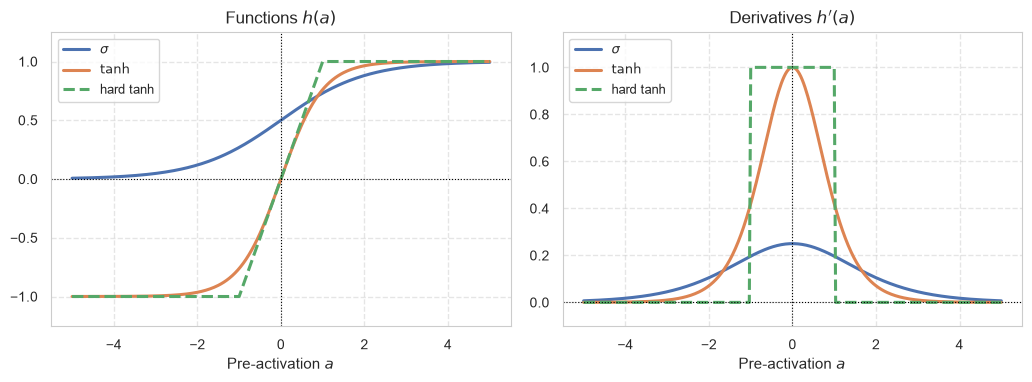

In [5]:
# Functions and their derivatives on a dense grid of pre-activations (used by all plots below)
a_grid = torch.linspace(-5.0, 5.0, 301)
values = {r"$\sigma$": sigmoid(a_grid), r"$\tanh$": tanh(a_grid), "hard tanh": hard_tanh(a_grid)}
slopes = {r"$\sigma$": d_sigmoid(a_grid), r"$\tanh$": d_tanh(a_grid),
          "hard tanh": d_hard_tanh(a_grid)}
hp.plot_function_panels(a_grid, [values, slopes],
                        titles=["Functions $h(a)$", "Derivatives $h'(a)$"],
                        ylims=[(-1.25, 1.25), (-0.1, 1.15)], dashed=["hard tanh"])

In [6]:
# Interactive tangent line h(a_0) + h'(a_0)(a - a_0): its slope is the local gradient
@interact(a=widgets.FloatSlider(value=0.0, min=-5.0, max=5.0, step=0.2, description="a"))
def show_tangents(a: float = 0.0) -> None:
    a_t = torch.tensor(a)
    sigma_panel = {r"$\sigma(a)$": sigmoid(a_grid),
                   f"tangent, slope {float(d_sigmoid(a_t)):.3f}":
                       sigmoid(a_t) + d_sigmoid(a_t) * (a_grid - a_t)}
    tanh_panel = {r"$\tanh(a)$": tanh(a_grid),
                  f"tangent, slope {float(d_tanh(a_t)):.3f}":
                      tanh(a_t) + d_tanh(a_t) * (a_grid - a_t)}
    hp.plot_function_panels(a_grid, [sigma_panel, tanh_panel],
                            ylims=[(-0.2, 1.2), (-1.25, 1.25)],
                            points=[(a, float(sigmoid(a_t))), (a, float(tanh(a_t)))])

interactive(children=(FloatSlider(value=0.0, description='a', max=5.0, min=-5.0, step=0.2), Output()), _dom_cl…

## The Vanishing Gradient Problem

- **Problem:** the derivative curves show that as $\lvert a \rvert$ grows, both $\sigma'(a)$ and $\tanh'(a)$ decay to zero **exponentially**: the units **saturate**.
  $$\lim_{\lvert a \rvert \to \infty} \sigma'(a) = 0, \qquad \lim_{\lvert a \rvert \to \infty} \tanh'(a) = 0$$
- **Activation factors in the chain rule:** take a chain of $L$ layers with one unit each, $a^{(l)} = w^{(l)} z^{(l-1)}$ and $z^{(l)} = h(a^{(l)})$, with input $z^{(0)} = x$. The gradient for the first weight is
  $$\frac{\partial E}{\partial w^{(1)}} = \frac{\partial E}{\partial z^{(L)}} \left[\prod_{l=2}^{L} h'(a^{(l)})\, w^{(l)}\right] h'(a^{(1)})\, x$$
  - Every layer contributes one **activation factor** $h'(a^{(l)})$. For the logistic sigmoid each is at most $0.25$, so the activation factors alone shrink the gradient by up to $(0.25)^L$: for $L = 6$, $(0.25)^6 \approx 0.00024$.
  - The **weight factors** $w^{(l)}$ multiply in as well: depending on their size, the product can vanish or **explode**. In real networks each factor is a layer's Jacobian matrix *(→ Lecture 08_backpropagation)*.

> ⚠️ **Important:** Saturating sigmoidal hidden units make vanishing gradients likely. This motivated modern deep learning to adopt **non-saturating** activations such as ReLU; normalizing the hidden layers controls the weight factors *(→ Lecture 09_regularization)*.

## Rectification: ReLU & The Dying Unit Problem

- **Problem:** saturating hidden units ($\sigma$, $\tanh$) shrink the backpropagated gradient in every layer (previous slide).
- **Solution:** the **Rectified Linear Unit (ReLU)** (Nair & Hinton, 2010; Glorot et al., 2011; Krizhevsky et al., 2012) does not saturate for $a > 0$ and is the standard default hidden activation:
  $$h(a) = \max(0, a)$$
- **Major Advantages:**
  - **Non-saturating:** the derivative is $\frac{dh}{da} = 1$ for all $a > 0$, so its activation factor never shrinks the backpropagated gradient there. This helps to alleviate the vanishing gradient problem; the weight factors still multiply in.
  - **Sparse representations:** exactly zero outputs for $a \le 0$ induce sparsity.
  - **Computational efficiency:** only a comparison (no exponentials or divisions), and well suited to low-precision hardware such as 8-bit fixed point.
- **Subgradient at $a = 0$:** the derivative is undefined at $a = 0$ (left limit $0$, right limit $1$). Software uses a value in $[0, 1]$, usually $0$; in practice this can be safely ignored.
- **New problem: "dying ReLU".** If the pre-activation $a = \mathbf{w}^\mathrm{T}\mathbf{x} + w_0$ of a hidden unit is negative for all training inputs, its gradient is $0$ for every input. The unit becomes an inactive "dead" neuron that never updates again.

<small>📖 *Source: [Nair, V., & Hinton, G. E. (2010). Rectified Linear Units Improve Restricted Boltzmann Machines. ICML 2010, 807–814](https://icml.cc/Conferences/2010/papers/432.pdf)*</small><br>
<small>📖 *Source: [Glorot, X., Bordes, A., & Bengio, Y. (2011). Deep Sparse Rectifier Neural Networks. AISTATS 2011, PMLR 15, 315–323](https://proceedings.mlr.press/v15/glorot11a.html)*</small><br>
<small>📖 *Source: [Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). ImageNet classification with deep convolutional neural networks. NeurIPS](https://proceedings.neurips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html)*</small>

## Leaky ReLU, Absolute Value, & Parametric ReLU

- **Problem:** a dead ReLU unit receives zero gradient for every input and never recovers (previous slide).
- **Solution: Leaky ReLU** (Maas et al., 2013) gives negative pre-activations a small positive slope $\alpha$:
  $$h(a) = \max(0, a) + \alpha \min(0, a) = \max(\alpha a, a), \quad 0 < \alpha < 1$$
  - The common default is $\alpha = 0.01$ (also PyTorch's `negative_slope`), used throughout this course. The derivative for $a < 0$ is $\alpha > 0$, guaranteeing a non-zero error signal.
- **Absolute Value Activation:**
  - Setting $\alpha = -1$ in the first form yields the symmetric absolute value activation:
    $$h(a) = \lvert a \rvert$$
- **Parametric ReLU (PReLU)** (He et al., 2015): the slope $\alpha$ is one more hyperparameter to choose by hand. PReLU instead lets each hidden unit learn its own $\alpha_j$ by gradient descent:
  $$\frac{\partial E}{\partial \alpha_j} = \sum_{n} \frac{\partial E}{\partial h(a_{nj})} \min(0, a_{nj})$$

<small>📖 *Source: Maas, A. L., Hannun, A. Y., & Ng, A. Y. (2013). Rectifier Nonlinearities Improve Neural Network Acoustic Models. ICML 2013, 28(3).*</small><br>
<small>📖 *Source: [He, K., Zhang, X., Ren, S., & Sun, J. (2015). Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification. ICCV 2015, 1026–1034](https://doi.org/10.1109/ICCV.2015.123)*</small>

## Exponential Linear Unit (ELU) & Softplus

- **Exponential Linear Unit (ELU)** (Clevert et al., 2015):
  - Problem: ReLU outputs are never negative, so the mean activation of a layer is positive (not zero-centred, as for $\sigma$).
  - Solution: negative outputs that saturate at $-\alpha$:
    $$h(a) = \begin{cases} a & a > 0 \\ \alpha(\exp(a) - 1) & a \le 0 \end{cases}$$
    Approaching $-\alpha$ smoothly as $a \to -\infty$ pushes the mean hidden unit activation closer to zero.
- **Softplus Function (Soft ReLU):**
  - Problem: some outputs must be strictly positive, e.g. a variance $\sigma^2 > 0$, but ReLU can return exactly $0$ and has a kink at $a = 0$.
  - Solution: a smooth approximation to ReLU that is always positive:
    $$\zeta(a) = \ln(1 + \exp(a))$$
    with $\zeta(a) \simeq a$ for $a \gg 1$ and $\zeta(a) \simeq 0$ for $a \ll -1$; as an output, $\sigma^2 = \zeta(a) > 0$.
<small>📖 *Source: [Clevert, D.-A., Unterthiner, T., & Hochreiter, S. (2015). Fast and Accurate Deep Network Learning by Exponential Linear Units (ELUs). ICLR 2016](https://doi.org/10.48550/arXiv.1511.07289)*</small>

In [7]:
# Mathematical implementations of the rectification family

def relu(a: torch.Tensor) -> torch.Tensor:
    """Rectified Linear Unit: max(0, a)."""
    return torch.relu(a)

def d_relu(a: torch.Tensor) -> torch.Tensor:
    """Subgradient of ReLU: 1 if a > 0 else 0."""
    return torch.where(a > 0.0, torch.tensor(1.0), torch.tensor(0.0))

def leaky_relu(a: torch.Tensor, alpha: float = 0.01) -> torch.Tensor:
    """Leaky ReLU: max(0, a) + alpha * min(0, a), which equals max(alpha * a, a) for 0 < alpha
    < 1."""
    return torch.where(a > 0.0, a, alpha * a)

def d_leaky_relu(a: torch.Tensor, alpha: float = 0.01) -> torch.Tensor:
    """Derivative of Leaky ReLU: 1 if a > 0 else alpha."""
    return torch.where(a > 0.0, torch.tensor(1.0), torch.tensor(float(alpha)))

def elu(a: torch.Tensor, alpha: float = 1.0) -> torch.Tensor:
    """Exponential Linear Unit: a if a > 0 else alpha * (exp(a) - 1)."""
    return torch.where(a > 0.0, a, alpha * (torch.exp(a) - 1.0))

def d_elu(a: torch.Tensor, alpha: float = 1.0) -> torch.Tensor:
    """Derivative of ELU: 1 if a > 0 else alpha * exp(a)."""
    return torch.where(a > 0.0, torch.tensor(1.0), alpha * torch.exp(a))

def softplus(a: torch.Tensor) -> torch.Tensor:
    """Softplus (soft ReLU): ln(1 + exp(a))."""
    return F.softplus(a)

def d_softplus(a: torch.Tensor) -> torch.Tensor:
    """Derivative of softplus: sigma(a)."""
    return torch.sigmoid(a)

In [8]:
# Concrete numerical demonstration of the rectification family
a_test = torch.tensor([-3.0, -1.0, 0.0, 1.0, 3.0])

display(Markdown(rf"""
- Pre-activations $a = {hp.format_vector(a_test, transpose=False)}$
- $\mathrm{{ReLU}}(a) = \max(0, a) = {hp.format_vector(relu(a_test), transpose=False)}$
- Leaky $\mathrm{{ReLU}}$, $\alpha = 0.01$:
  ${hp.format_vector(leaky_relu(a_test, alpha=0.01), transpose=False)}$
- $\mathrm{{ELU}}$, $\alpha = 1$: ${hp.format_vector(elu(a_test, alpha=1.0), transpose=False)}$
- Softplus $\zeta(a) = \ln(1 + \exp(a)) = {hp.format_vector(softplus(a_test), transpose=False)}$
"""))


- Pre-activations $a = (-3, -1, 0, 1, 3)$
- $\mathrm{ReLU}(a) = \max(0, a) = (0, 0, 0, 1, 3)$
- Leaky $\mathrm{ReLU}$, $\alpha = 0.01$:
  $(-0.03, -0.01, 0, 1, 3)$
- $\mathrm{ELU}$, $\alpha = 1$: $(-0.9502, -0.6321, 0, 1, 3)$
- Softplus $\zeta(a) = \ln(1 + \exp(a)) = (0.0486, 0.3133, 0.6931, 1.3133, 3.0486)$


### Softplus Identities

Four identities link softplus $\zeta$ and the logistic sigmoid $\sigma$ (verified in the next cell):
1. Difference identity: $\zeta(a) - \zeta(-a) = a$
2. Log-sigmoid identity: $\ln \sigma(a) = -\zeta(-a)$
3. Derivative identity: $\frac{d\zeta}{da} = \sigma(a)$ (the derivative of softplus is the logistic sigmoid!)
4. Inverse softplus: $\zeta^{-1}(y) = \ln(\exp(y) - 1)$ for $y > 0$

In [9]:
# Verification of the four softplus identities (largest deviation over the sample points)
a_autograd = a_test.clone().requires_grad_(True)
# d zeta / da by automatic differentiation
(d_zeta_autograd,) = torch.autograd.grad(softplus(a_autograd).sum(), a_autograd)

deviations = {
    r"1. $\zeta(a) - \zeta(-a) = a$": softplus(a_test) - softplus(-a_test) - a_test,
    r"2. $\ln \sigma(a) = -\zeta(-a)$": torch.log(sigmoid(a_test)) + softplus(-a_test),
    r"3. $\frac{d\zeta}{da} = \sigma(a)$ (autograd)": d_zeta_autograd - sigmoid(a_test),
    r"4. $\zeta^{-1}(\zeta(a)) = \ln(\exp(\zeta(a)) - 1) = a$":
        torch.log(torch.expm1(softplus(a_test))) - a_test,
}
for identity, deviation in deviations.items():
    display(Markdown(rf"{identity}: largest deviation ${float(deviation.abs().max()):.2e}$"))

1. $\zeta(a) - \zeta(-a) = a$: largest deviation $5.96e-08$

2. $\ln \sigma(a) = -\zeta(-a)$: largest deviation $2.98e-08$

3. $\frac{d\zeta}{da} = \sigma(a)$ (autograd): largest deviation $0.00e+00$

4. $\zeta^{-1}(\zeta(a)) = \ln(\exp(\zeta(a)) - 1) = a$: largest deviation $1.19e-07$

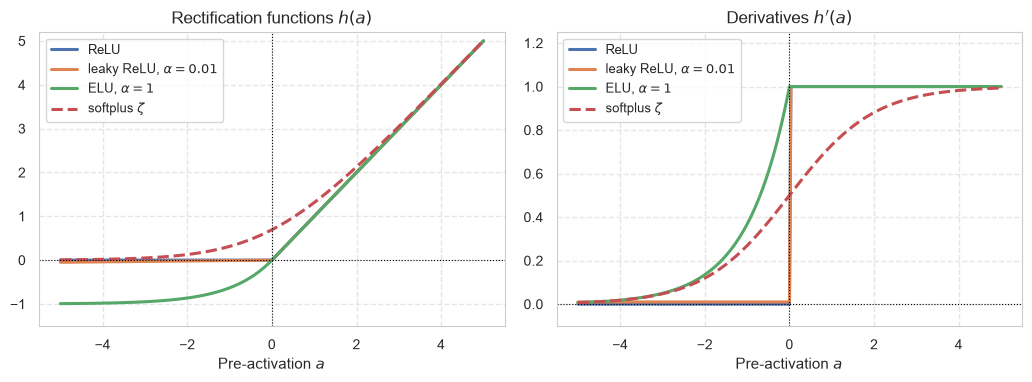

In [10]:
# Rectification functions and their derivatives on the grid a_grid
values = {"ReLU": relu(a_grid), r"leaky ReLU, $\alpha = 0.01$": leaky_relu(a_grid),
          r"ELU, $\alpha = 1$": elu(a_grid), r"softplus $\zeta$": softplus(a_grid)}
slopes = {"ReLU": d_relu(a_grid), r"leaky ReLU, $\alpha = 0.01$": d_leaky_relu(a_grid),
          r"ELU, $\alpha = 1$": d_elu(a_grid), r"softplus $\zeta$": d_softplus(a_grid)}
hp.plot_function_panels(a_grid, [values, slopes],
                        titles=["Rectification functions $h(a)$", "Derivatives $h'(a)$"],
                        ylims=[(-1.5, 5.2), (-0.1, 1.25)], dashed=[r"softplus $\zeta$"])

In [11]:
# Interactive slope alpha for a < 0: alpha = -1 gives |a|, alpha = 0 ReLU, alpha = 1 the identity
@interact(alpha=widgets.FloatSlider(value=0.01, min=-1.0, max=1.0, step=0.01,
                                    description=r"$\alpha$"))
def show_leaky_relu(alpha: float = 0.01) -> None:
    values = {rf"$\max(0, a) + \alpha \min(0, a)$, $\alpha = {alpha:.2f}$":
                  leaky_relu(a_grid, alpha=alpha),
              "ReLU": relu(a_grid)}
    slopes = {rf"$h'(a)$, $\alpha = {alpha:.2f}$": d_leaky_relu(a_grid, alpha=alpha)}
    hp.plot_function_panels(a_grid, [values, slopes],
                            titles=["Function $h(a)$", "Derivative $h'(a)$"],
                            ylims=[(-5.2, 5.2), (-1.25, 1.25)], dashed=["ReLU"])

interactive(children=(FloatSlider(value=0.01, description='$\\alpha$', max=1.0, min=-1.0, step=0.01), Output()…

## Smooth Self-Gated Activations: Swish & SiLU

- **Problem:** ReLU switches abruptly at $a = 0$ and returns exactly $0$, with zero gradient, for every negative input.
- **Solution: a smooth gate.** The **Swish function** (Ramachandran, Zoph, & Le, 2017), found by an automated search over candidate activations, multiplies the input by a soft gate:
  $$h(a) = a \sigma(\beta a)$$
  - The input $a$ acts as its own gate via the logistic sigmoid $\sigma(\beta a)$; the parameter $\beta$ can be fixed or learned.
- **Behavior Across the Parameter Continuum:**
  - As $\beta \to 0$: $\sigma(\beta a) \to 0.5$, so $h(a) \to \frac{a}{2}$ (scaled linear function).
  - For $\beta = 1$: **SiLU (Sigmoid Linear Unit)** (Hendrycks & Gimpel, 2016), used as a plain activation (e.g. in the U-Net of Stable Diffusion) and inside the gated **SwiGLU** feed-forward blocks of LLaMA 2/3 and Mistral.
  - As $\beta \to \infty$: $\sigma(\beta a) \to \mathrm{hardlim}(a)$, so $h(a) \to \max(0, a) = \mathrm{ReLU}(a)$!
- **First Derivative:**
  $$\frac{dh}{da} = \beta a \sigma(\beta a)(1 - \sigma(\beta a)) + \sigma(\beta a) = \beta h(a) + \sigma(\beta a)(1 - \beta h(a))$$
- Non-monotonicity: for $\beta > 0$, Swish has a small negative dip with minimum $h \approx -0.278/\beta$ at $a \approx -1.278/\beta$ (checked below), providing a smooth, regularizing inductive bias.

<small>📖 *Source: [Ramachandran, P., Zoph, B., & Le, Q. V. (2017). Searching for Activation Functions. arXiv:1710.05941](https://doi.org/10.48550/arXiv.1710.05941)*</small><br>
<small>📖 *Source: [Hendrycks, D., & Gimpel, K. (2016). Gaussian Error Linear Units (GELUs). arXiv:1606.08415](https://doi.org/10.48550/arXiv.1606.08415)*</small>

## Probit, Error Function (erf), & GELU

- **Problem:** the logistic sigmoid is one convenient S-shaped curve. Which curve follows from a model of how a noisy decision arises?
- **Solution: the probit function.** In a **noisy threshold model**, $t = 1$ if $a \ge \theta$ and $t = 0$ otherwise, with a random threshold $\theta \sim \mathcal{N}(0, 1)$. Then $p(t = 1 \mid a)$ is the cumulative distribution function of the standard Gaussian:
  $$\Phi(a) = \int_{-\infty}^a \mathcal{N}(\theta \mid 0, 1)\, d\theta = \frac{1}{2}\left[1 + \operatorname{erf}\left(\frac{a}{\sqrt{2}}\right)\right]$$
  - Here $\operatorname{erf}(a) = \frac{2}{\sqrt{\pi}}\int_0^a \exp(-\theta^2)\, d\theta$ is the standard Gauss error function. Some texts define erf with $\exp(-\theta^2/2)$ instead and then write $\Phi(a) = \frac{1}{2}\left[1 + \frac{1}{\sqrt{2}}\operatorname{erf}(a)\right]$: the formulas look different, but $\Phi$ is the same function.
- **Derivative Matching & Scaled Probit:** $\Phi'(0) = \frac{1}{\sqrt{2\pi}} \approx 0.3989$, while $\sigma'(0) = 0.25$. With $\lambda = \sqrt{\pi / 8} \approx 0.6267$, the scaled probit $\Phi(\lambda a)$ has the matching slope $\lambda \Phi'(0) = 0.25$.
- **Tail Decay & Outlier Sensitivity:**
  - Logistic sigmoid tails decay exponentially: $\sigma(a) \approx \exp(-\lvert a \rvert)$ as $a \to -\infty$ (and $1 - \sigma(a) \approx \exp(-a)$ as $a \to \infty$).
  - Probit tails decay like a Gaussian, $\exp(-a^2/2)$, much faster. A mislabelled point far on the wrong side then has the error $-\ln \Phi(a) \approx a^2/2$ instead of $\approx \lvert a \rvert$, so probit regression is more sensitive to outliers.
- **Gaussian Error Linear Unit (GELU) (Hendrycks & Gimpel, 2016):** the same smooth gate as SiLU, with $\Phi$ in place of $\sigma$: the input $a$ is weighted by its standard Gaussian cumulative probability, $\mathrm{GELU}(a) = a \Phi(a)$. Standard in Transformers (BERT, GPT, ViT).

<small>📖 *Source: [Hendrycks, D., & Gimpel, K. (2016). Gaussian Error Linear Units (GELUs). arXiv:1606.08415](https://doi.org/10.48550/arXiv.1606.08415)*</small>

In [12]:
# Mathematical implementations of Swish, Probit, and GELU

def swish(a: torch.Tensor, beta: float = 1.0) -> torch.Tensor:
    """Swish activation: h(a) = a * sigma(beta * a)."""
    return a * torch.sigmoid(beta * a)

def d_swish(a: torch.Tensor, beta: float = 1.0) -> torch.Tensor:
    """Analytical derivative of Swish."""
    s = torch.sigmoid(beta * a)
    return beta * a * s * (1.0 - s) + s

def probit(a: torch.Tensor) -> torch.Tensor:
    """Standard normal CDF: Phi(a) = 0.5 * (1 + erf(a / sqrt(2)))."""
    return 0.5 * (1.0 + torch.erf(a / math.sqrt(2.0)))

def scaled_probit(a: torch.Tensor) -> torch.Tensor:
    """Scaled probit matching sigmoid slope at origin: Phi(sqrt(pi/8) * a)."""
    scale = math.sqrt(math.pi / 8.0)
    return probit(scale * a)

def d_probit(a: torch.Tensor) -> torch.Tensor:
    """Derivative of standard probit: standard normal PDF N(a | 0, 1)."""
    return (1.0 / math.sqrt(2.0 * math.pi)) * torch.exp(-0.5 * a ** 2)

def d_scaled_probit(a: torch.Tensor) -> torch.Tensor:
    """Derivative of scaled probit with scale sqrt(pi/8)."""
    scale = math.sqrt(math.pi / 8.0)
    return scale * d_probit(scale * a)

def gelu(a: torch.Tensor) -> torch.Tensor:
    """Gaussian Error Linear Unit: GELU(a) = a * Phi(a)."""
    return 0.5 * a * (1.0 + torch.erf(a / math.sqrt(2.0)))

def d_gelu(a: torch.Tensor) -> torch.Tensor:
    """Analytical derivative of GELU."""
    phi_a = probit(a)
    gaussian_pdf = (1.0 / math.sqrt(2.0 * math.pi)) * torch.exp(-0.5 * a ** 2)
    return phi_a + a * gaussian_pdf


In [13]:
# Concrete numerical comparison: probit vs. logistic sigmoid, slopes and tails
a_eval = torch.tensor([-4.0, -2.0, -1.0, 0.0, 1.0, 2.0, 4.0])
a_zero = torch.tensor(0.0)     # slopes at the origin: lambda^2 = pi / 8 matches them
# tails: error -ln p(t = 1 | a) of a point with t = 1 far on the wrong side
a_far = torch.tensor(-4.0)

display(Markdown(rf"""
- Pre-activations $a = {hp.format_vector(a_eval, transpose=False)}$
- Sigmoid $\sigma(a) = {hp.format_vector(sigmoid(a_eval), transpose=False)}$
- Standard probit $\Phi(a) = {hp.format_vector(probit(a_eval), transpose=False)}$
- Scaled probit $\Phi(\lambda a) = {hp.format_vector(scaled_probit(a_eval), transpose=False)}$
  with $\lambda^2 = \pi / 8$
- Slopes at $a = 0$: $\sigma'(0) = {float(d_sigmoid(a_zero)):.4f}$,
  $\Phi'(0) = {float(d_probit(a_zero)):.4f}$,
  $\lambda \Phi'(0) = {float(d_scaled_probit(a_zero)):.4f}$
- Error at $a = -4$: $-\ln \sigma(a) = {float(-torch.log(sigmoid(a_far))):.2f}$,
  $-\ln \Phi(a) = {float(-torch.log(probit(a_far))):.2f}$
"""))


- Pre-activations $a = (-4, -2, -1, 0, 1, 2, 4)$
- Sigmoid $\sigma(a) = (0.018, 0.1192, 0.2689, 0.5, 0.7311, 0.8808, 0.982)$
- Standard probit $\Phi(a) = (0, 0.0228, 0.1587, 0.5, 0.8413, 0.9772, 1)$
- Scaled probit $\Phi(\lambda a) = (0.0061, 0.105, 0.2654, 0.5, 0.7346, 0.895, 0.9939)$
  with $\lambda^2 = \pi / 8$
- Slopes at $a = 0$: $\sigma'(0) = 0.2500$,
  $\Phi'(0) = 0.3989$,
  $\lambda \Phi'(0) = 0.2500$
- Error at $a = -4$: $-\ln \sigma(a) = 4.02$,
  $-\ln \Phi(a) = 10.36$


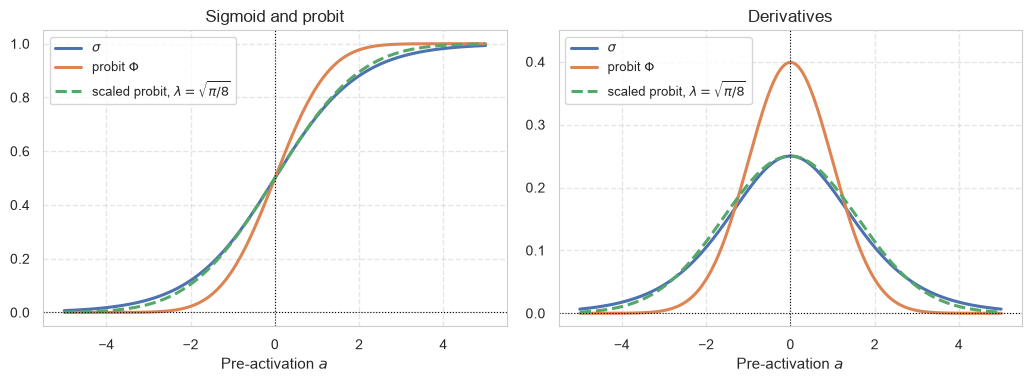

In [14]:
# Sigmoid vs. standard and scaled probit, and their derivatives
values = {r"$\sigma$": sigmoid(a_grid), r"probit $\Phi$": probit(a_grid),
          r"scaled probit, $\lambda = \sqrt{\pi/8}$": scaled_probit(a_grid)}
slopes = {r"$\sigma$": d_sigmoid(a_grid), r"probit $\Phi$": d_probit(a_grid),
          r"scaled probit, $\lambda = \sqrt{\pi/8}$": d_scaled_probit(a_grid)}
hp.plot_function_panels(a_grid, [values, slopes], titles=["Sigmoid and probit", "Derivatives"],
                        ylims=[(-0.05, 1.05), (-0.02, 0.45)],
                        dashed=[r"scaled probit, $\lambda = \sqrt{\pi/8}$"])

In [15]:
# Concrete numerical demonstration of gating: SiLU vs. GELU vs. ReLU
a_sample_grid = torch.tensor([-2.5, -1.0, 0.0, 1.0, 2.5])

# Checks: GELU against PyTorch's F.gelu, the analytical GELU derivative against autograd
a_autograd = a_sample_grid.clone().requires_grad_(True)
(d_gelu_autograd,) = torch.autograd.grad(gelu(a_autograd).sum(), a_autograd)
dev_gelu = float(torch.max(torch.abs(gelu(a_sample_grid) - F.gelu(a_sample_grid))))
dev_d_gelu = float(torch.max(torch.abs(d_gelu(a_sample_grid) - d_gelu_autograd)))

In [16]:
display(Markdown(rf"""
- Pre-activations $a = {hp.format_vector(a_sample_grid, transpose=False)}$
- Probit gate $\Phi(a) = {hp.format_vector(probit(a_sample_grid), transpose=False)}$
- Sigmoid gate $\sigma(a) = {hp.format_vector(sigmoid(a_sample_grid), transpose=False)}$
- $\mathrm{{GELU}}(a) = a \Phi(a) = {hp.format_vector(gelu(a_sample_grid), transpose=False)}$
- $\mathrm{{SiLU}}(a) = a \sigma(a)$
  $= {hp.format_vector(swish(a_sample_grid, beta=1.0), transpose=False)}$
- $\mathrm{{ReLU}}(a) = \max(0, a) = {hp.format_vector(relu(a_sample_grid), transpose=False)}$
- Agreement with `F.gelu`: largest deviation ${dev_gelu:.2e}$
- $\mathrm{{GELU}}'(a) = \Phi(a) + a\,\mathcal{{N}}(a \mid 0, 1)$ against autograd: largest
  deviation ${dev_d_gelu:.2e}$
"""))


- Pre-activations $a = (-2.5, -1, 0, 1, 2.5)$
- Probit gate $\Phi(a) = (0.0062, 0.1587, 0.5, 0.8413, 0.9938)$
- Sigmoid gate $\sigma(a) = (0.0759, 0.2689, 0.5, 0.7311, 0.9241)$
- $\mathrm{GELU}(a) = a \Phi(a) = (-0.0155, -0.1587, 0, 0.8413, 2.4845)$
- $\mathrm{SiLU}(a) = a \sigma(a)$
  $= (-0.1896, -0.2689, 0, 0.7311, 2.3104)$
- $\mathrm{ReLU}(a) = \max(0, a) = (0, 0, 0, 1, 2.5)$
- Agreement with `F.gelu`: largest deviation $0.00e+00$
- $\mathrm{GELU}'(a) = \Phi(a) + a\,\mathcal{N}(a \mid 0, 1)$ against autograd: largest
  deviation $1.49e-08$


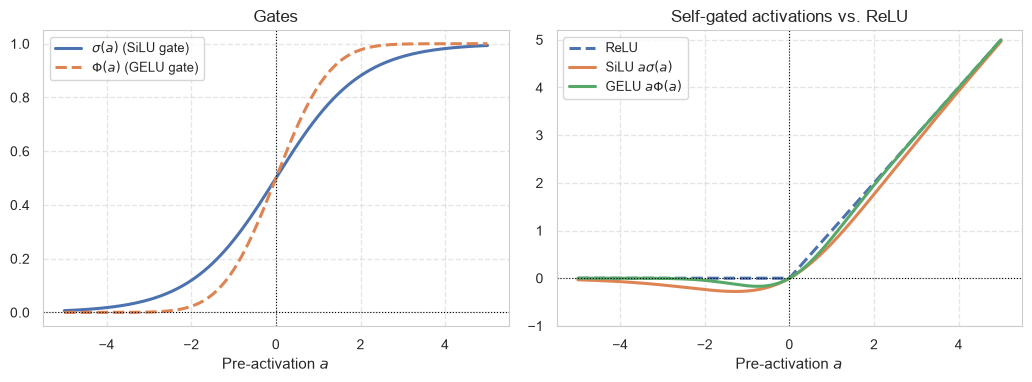

In [17]:
# The gates sigma(a), Phi(a) and the resulting self-gated activations
gates = {r"$\sigma(a)$ (SiLU gate)": sigmoid(a_grid), r"$\Phi(a)$ (GELU gate)": probit(a_grid)}
activations = {"ReLU": relu(a_grid), r"SiLU $a\sigma(a)$": swish(a_grid, beta=1.0),
               r"GELU $a\Phi(a)$": gelu(a_grid)}
hp.plot_function_panels(a_grid, [gates, activations],
                        titles=["Gates", "Self-gated activations vs. ReLU"],
                        ylims=[(-0.05, 1.05), (-1.0, 5.2)],
                        dashed=[r"$\Phi(a)$ (GELU gate)", "ReLU"])

In [18]:
# Lower end of the ranges: minimum of Swish (beta = 1, 2) and GELU on a fine grid
a_fine = torch.linspace(-5.0, 0.0, 500001, dtype=torch.float64)
gated = {r"Swish, $\beta = 1$": swish(a_fine, beta=1.0),
         r"Swish, $\beta = 2$": swish(a_fine, beta=2.0), "GELU": gelu(a_fine)}
for name, h_fine in gated.items():
    i_min = int(torch.argmin(h_fine))
    display(Markdown(rf"{name}: minimum $h = {float(h_fine[i_min]):.4f}$ at "
                     rf"$a = {float(a_fine[i_min]):.3f}$"))

Swish, $\beta = 1$: minimum $h = -0.2785$ at $a = -1.278$

Swish, $\beta = 2$: minimum $h = -0.1392$ at $a = -0.639$

GELU: minimum $h = -0.1700$ at $a = -0.752$

In [19]:
# Interactive Swish parameter beta: a / 2 for beta = 0, SiLU for beta = 1, close to ReLU for
# large beta
@interact(beta=widgets.FloatSlider(value=1.0, min=0.0, max=10.0, step=0.2, description=r"$\beta$"))
def show_swish(beta: float = 1.0) -> None:
    values = {rf"Swish, $\beta = {beta:.1f}$": swish(a_grid, beta=beta), "ReLU": relu(a_grid),
              r"$a/2$": 0.5 * a_grid}
    slopes = {rf"Swish, $\beta = {beta:.1f}$": d_swish(a_grid, beta=beta), "ReLU": d_relu(a_grid)}
    hp.plot_function_panels(a_grid, [values, slopes],
                            titles=[r"Swish $h(a) = a\sigma(\beta a)$", "Derivative $h'(a)$"],
                            ylims=[(-1.0, 5.2), (-0.3, 1.25)], dashed=["ReLU", r"$a/2$"])

interactive(children=(FloatSlider(value=1.0, description='$\\beta$', max=10.0, step=0.2), Output()), _dom_clas…

## Normalization & Probability Mapping: Softmax

- **Problem:** for $K > 2$ classes, the network has to output a categorical distribution: $K$ probabilities that are positive and sum to one. $K$ separate sigmoids give values in $(0, 1)$ that need not sum to one.
- **Solution:** the **softmax function** (normalized exponential) maps a vector of pre-activations (**logits**) $\mathbf{a} = (a_1, \dots, a_K)^\mathrm{T} \in \mathbb{R}^K$ to a categorical distribution $\mathbf{y} = \mathrm{softmax}(\mathbf{a})$ over $K$ classes:
  $$y_k = \frac{\exp(a_k)}{\sum_{j=1}^K \exp(a_j)}, \qquad k = 1, \dots, K$$
- **Not element-wise:** every output $y_k$ depends on *all* logits through the normalization. The outputs lie on the **probability simplex**, $y_k > 0$ and $\sum_{k=1}^K y_k = 1$, automatically.
- **Smooth Approximation to Argmax:** if $a_k \gg a_j$ for all $j \ne k$, then $y_k \to 1$ and $y_j \to 0$.
- **Derivative = Jacobian Matrix:** because softmax maps a vector to a vector, its derivative is the $K \times K$ Jacobian
  $$\frac{\partial y_k}{\partial a_j} = y_k(I_{kj} - y_j), \qquad \mathbf{J} = \mathrm{diag}(\mathbf{y}) - \mathbf{y}\mathbf{y}^\mathrm{T}$$
  where $I_{kj}$ are the elements of the identity matrix. It drives backpropagation through softmax outputs *(→ Lecture 08_backpropagation)* and gives the gradient of multi-class logistic regression *(→ Lecture 05_classification)*.
  - Cross-coupling: increasing logit $a_j$ decreases every other probability $y_k$, $k \ne j$ (off-diagonal entries $-y_k y_j < 0$).

## Softmax with Temperature (Distillation & Sampling)

- **Problem:** sometimes the distribution should be flatter or more peaked than the network's own output: soft targets in knowledge distillation (Hinton et al., 2015), or more or less diverse tokens when sampling from a language model.
- **Solution:** a scalar **temperature** $\tau > 0$ divides the logits:
  $$\mathbf{y} = \mathrm{softmax}(\mathbf{a} / \tau), \qquad y_k = \frac{\exp(a_k / \tau)}{\sum_{j=1}^K \exp(a_j / \tau)}$$
- **Limiting Regimes of Temperature**, measured by the entropy $\mathrm{H}[\mathbf{y}] = -\sum_{k=1}^K y_k \ln y_k$ *(from Lecture 03_information)*:
  - **High temperature ($\tau \to \infty$):** all exponents approach $0$, producing the **uniform distribution** $y_k \to 1/K$ with maximum entropy $\mathrm{H} = \ln K$.
  - **Standard softmax ($\tau = 1$):** the unchanged categorical probabilities.
  - **Low temperature ($\tau \to 0^+$):** collapses into a **one-hot** vector on the largest logit, with entropy $\mathrm{H} \to 0$.
- **Temperature in Large Language Models:** $\tau \to 0$ gives greedy selection of the most probable token; larger $\tau$ makes the generated text more diverse.

<small>📖 *Source: [Hinton, G., Vinyals, O., & Dean, J. (2015). Distilling the Knowledge in a Neural Network. arXiv:1503.02531](https://doi.org/10.48550/arXiv.1503.02531)*</small>

## Numerical Stability: The Log-Sum-Exp Trick

- **Problem: overflow.** In IEEE 754 arithmetic, $\exp(a)$ overflows to `inf` for $a > 88.7$ in float32 ($a > 709.7$ in float64). For logits $(1000, 1001, 1002)$, naive softmax returns $\frac{\infty}{\infty} =$ `nan`.
- **Solution: shift invariance.** Adding the same constant $c \in \mathbb{R}$ to every logit, $\mathbf{a} + c\mathbf{1}$ with $\mathbf{1} = (1, \dots, 1)^\mathrm{T}$, leaves the output unchanged, $\mathrm{softmax}(\mathbf{a} + c\mathbf{1}) = \mathrm{softmax}(\mathbf{a})$:
  $$\frac{\exp(a_k + c)}{\sum_j \exp(a_j + c)} = \frac{\exp(c)\exp(a_k)}{\exp(c)\sum_j \exp(a_j)} = y_k$$
  **Stable softmax** shifts by $m = \max_j a_j$: every exponent $a_k - m \le 0$, so no exponential exceeds $\exp(0) = 1$ and overflow cannot occur.
- **Problem: underflow in the logarithm.** The cross-entropy *(from Lecture 03_information)* needs $\ln y_k$, but a tiny probability can underflow to $0$, and $\ln 0 = -\infty$.
- **Solution: log-softmax via log-sum-exp**, computed directly from the logits:
  $$\ln y_k = a_k - m - \ln \sum_{j=1}^K \exp(a_j - m)$$
  This never takes the logarithm of a probability that has underflowed to $0$. That is why PyTorch's `CrossEntropyLoss` and `BCEWithLogitsLoss` take **logits**, not probabilities.

In [20]:
# Mathematical implementations of naive vs. stabilized softmax, log-softmax and the softmax Jacobian

def naive_softmax(logits: torch.Tensor) -> torch.Tensor:
    """Naive unshifted softmax (vulnerable to numerical overflow)."""
    exp_vals = torch.exp(logits)
    return exp_vals / torch.sum(exp_vals)

def stable_softmax(logits: torch.Tensor, tau: float = 1.0) -> torch.Tensor:
    """Numerically stable softmax with temperature tau: shift by the largest logit, then divide
    by tau."""
    max_logit = torch.max(logits)
    scaled_shifted = (logits - max_logit) / tau
    exp_vals = torch.exp(scaled_shifted)
    return exp_vals / torch.sum(exp_vals)

def log_softmax(logits: torch.Tensor) -> torch.Tensor:
    """Log-softmax via log-sum-exp: ln y_k = a_k - m - ln sum_j exp(a_j - m), with m = max_j a_j."""
    m = torch.max(logits)
    return logits - m - torch.log(torch.sum(torch.exp(logits - m)))

def softmax_jacobian(y: torch.Tensor) -> torch.Tensor:
    """K x K Jacobian of softmax from its outputs y: J_kj = y_k * (I_kj - y_j), i.e. diag(y) -
    y y^T."""
    return torch.diag(y) - torch.outer(y, y)

def categorical_entropy(y: torch.Tensor) -> float:
    """Entropy H[y] = -sum_k y_k ln y_k of a categorical distribution, in nats."""
    y_safe = torch.clamp(y, min=1e-12)
    return -float(torch.sum(y_safe * torch.log(y_safe)))

In [21]:
# Numerical comparison: naive overflow vs. stabilized softmax and log-softmax
large_logits = torch.tensor([1000.0, 1001.0, 1002.0])
stable_res = stable_softmax(large_logits)

# A probability that underflows in float32: logits (0, -120), y_2 = exp(-120) / (1 + exp(-120))
# < 1e-45
small_logits = torch.tensor([0.0, -120.0])

display(Markdown(rf"""
- Large logits $\mathbf{{a}} = {hp.format_vector(large_logits)}$:
  1. Naive softmax (unshifted), numerical overflow:
     $\mathbf{{y}} = {hp.format_vector(naive_softmax(large_logits))}$
  2. Stabilized softmax (shifted by $m = \max_j a_j$):
     $\mathbf{{y}} = {hp.format_vector(stable_res)}$,
     $\sum_k y_k = {float(torch.sum(stable_res)):.4f}$
- Logits $\mathbf{{a}} = {hp.format_vector(small_logits)}$, values $\ln y_k$:
  1. Logarithm of softmax: ${hp.format_vector(torch.log(stable_softmax(small_logits)))}$
  2. Log-sum-exp: ${hp.format_vector(log_softmax(small_logits))}$
  3. PyTorch's `F.log_softmax`: ${hp.format_vector(F.log_softmax(small_logits, dim=0))}$
"""))


- Large logits $\mathbf{a} = (1000, 1001, 1002)^\mathrm{T}$:
  1. Naive softmax (unshifted), numerical overflow:
     $\mathbf{y} = (\mathrm{NaN}, \mathrm{NaN}, \mathrm{NaN})^\mathrm{T}$
  2. Stabilized softmax (shifted by $m = \max_j a_j$):
     $\mathbf{y} = (0.09, 0.2447, 0.6652)^\mathrm{T}$,
     $\sum_k y_k = 1.0000$
- Logits $\mathbf{a} = (0, -120)^\mathrm{T}$, values $\ln y_k$:
  1. Logarithm of softmax: $(0, -\infty)^\mathrm{T}$
  2. Log-sum-exp: $(0, -120)^\mathrm{T}$
  3. PyTorch's `F.log_softmax`: $(0, -120)^\mathrm{T}$


In [22]:
# Softmax Jacobian on moderate logits: symmetric, every row sums to 0 (shift invariance), equal
# to autograd
a_moderate = torch.tensor([2.0, 1.0, 0.0])
y_eval = stable_softmax(a_moderate)
J = softmax_jacobian(y_eval)
J_autograd = torch.autograd.functional.jacobian(stable_softmax, a_moderate)

display(Markdown(rf"Softmax output vector $\mathbf{{y}} = {hp.format_vector(y_eval)}$"))
display(Markdown(r"Full Jacobian matrix $\frac{\partial y_k}{\partial a_j} = y_k (I_{kj} - y_j)$:"))
print(np.round(J.numpy(), 3))
display(Markdown(r"Symmetric: $\max \lvert \mathbf{J} - \mathbf{J}^\mathrm{T} \rvert = "
                 rf"{float((J - J.T).abs().max()):.1e}$; "
                 r"row sums: $\max_k \lvert \sum_j J_{kj} \rvert = "
                 rf"{float(J.sum(dim=1).abs().max()):.1e}$; "
                 r"against autograd: $\max \lvert \mathbf{J} - "
                 r"\mathbf{J}_\mathrm{autograd} \rvert = "
                 rf"{float((J - J_autograd).abs().max()):.1e}$"))

Softmax output vector $\mathbf{y} = (0.6652, 0.2447, 0.09)^\mathrm{T}$

Full Jacobian matrix $\frac{\partial y_k}{\partial a_j} = y_k (I_{kj} - y_j)$:

[[ 0.223 -0.163 -0.06 ]
 [-0.163  0.185 -0.022]
 [-0.06  -0.022  0.082]]


Symmetric: $\max \lvert \mathbf{J} - \mathbf{J}^\mathrm{T} \rvert = 0.0e+00$; row sums: $\max_k \lvert \sum_j J_{kj} \rvert = 1.9e-08$; against autograd: $\max \lvert \mathbf{J} - \mathbf{J}_\mathrm{autograd} \rvert = 1.5e-08$

In [23]:
# Temperature-scaled softmax for fixed logits, computed for three temperatures and for every
# slider position
sample_logits = torch.tensor([2.5, 1.2, 0.2, -1.0])
class_labels = ["$a_1 = 2.5$", "$a_2 = 1.2$", "$a_3 = 0.2$", "$a_4 = -1.0$"]

lines = [rf"- Logits $\mathbf{{a}} = {hp.format_vector(sample_logits)}$ of "
         rf"$K = {len(sample_logits)}$ classes (maximum entropy "
         rf"$\ln K = {math.log(len(sample_logits)):.3f}$ nats)"]
for tau in (0.1, 1.0, 4.0):
    y_tau = stable_softmax(sample_logits, tau=tau)
    lines.append(rf"- $\tau = {tau}$: $\mathbf{{y}} = \mathrm{{softmax}}(\mathbf{{a}} / \tau) "
                 rf"= {hp.format_vector(y_tau)}$, entropy $\mathrm{{H}}[\mathbf{{y}}] = "
                 rf"{categorical_entropy(y_tau):.3f}$ nats")
display(Markdown("\n".join(lines)))

# slider positions 0.05, 0.10, ..., 4.00
tau_values = [round(0.05 * i, 2) for i in range(1, 81)]
y_by_tau = {tau: stable_softmax(sample_logits, tau=tau) for tau in tau_values}
entropy_by_tau = {tau: categorical_entropy(y) for tau, y in y_by_tau.items()}

- Logits $\mathbf{a} = (2.5, 1.2, 0.2, -1)^\mathrm{T}$ of $K = 4$ classes (maximum entropy $\ln K = 1.386$ nats)
- $\tau = 0.1$: $\mathbf{y} = \mathrm{softmax}(\mathbf{a} / \tau) = (1, 0, 0, 0)^\mathrm{T}$, entropy $\mathrm{H}[\mathbf{y}] = 0.000$ nats
- $\tau = 1.0$: $\mathbf{y} = \mathrm{softmax}(\mathbf{a} / \tau) = (0.7128, 0.1943, 0.0715, 0.0215)^\mathrm{T}$, entropy $\mathrm{H}[\mathbf{y}] = 0.831$ nats
- $\tau = 4.0$: $\mathbf{y} = \mathrm{softmax}(\mathbf{a} / \tau) = (0.3701, 0.2674, 0.2082, 0.1543)^\mathrm{T}$, entropy $\mathrm{H}[\mathbf{y}] = 1.336$ nats

In [24]:
# Interactive temperature: the callback only plots the precomputed distributions
@interact(tau=widgets.SelectionSlider(options=tau_values, value=1.0, description=r"$\tau$"))
def show_temperature(tau: float = 1.0) -> None:
    hp.plot_categorical_probabilities(class_labels, {rf"$\tau = {tau:.2f}$": y_by_tau[tau]},
                                      title=rf"Softmax with temperature $\tau = {tau:.2f}$: "
                                            rf"entropy {entropy_by_tau[tau]:.3f} nats",
                                      ylim=(0.0, 1.05))

interactive(children=(SelectionSlider(description='$\\tau$', index=19, options=(0.05, 0.1, 0.15, 0.2, 0.25, 0.…

## Hidden vs. Output Activations: Architectural Taxonomy

- In modern deep learning, the choice of activation function is governed by its **position in the network**:

| Characteristic | Hidden-layer activations $h(a)$ | Output-layer activations $f(a)$ |
| :-- | :-- | :-- |
| **Primary purpose** | Break linearity, enable universal function approximation *(→ Lecture 06_deep_networks)* | Map pre-activations to the support of the targets |
| **Design criteria** | Good gradient propagation, no dying units, cheap to compute | Matched to the likelihood $p(t \mid \mathbf{x})$, calibrated probabilities |
| **Standard choices** | ReLU, leaky ReLU, SiLU / Swish, GELU | Identity, logistic sigmoid, softmax, exponential |
| **Coupling to the loss** | Indirect, through backpropagation | **Tightly coupled** to the conditional distribution $p(t \mid \mathbf{x})$ |

> 💡 **Key Takeaway:** You can choose almost any differentiable nonlinearity for hidden layers, but the output activation is dictated by the probability distribution of your targets.

## Canonical Link Functions & The Simple Gradient $y - t$

- A **generalized linear model** (Nelder & Wedderburn, 1972) predicts the conditional mean $y = \mathbb{E}[t \mid \mathbf{x}]$ as $y = f(a)$ with $a = \mathbf{w}^\mathrm{T}\boldsymbol{\phi}(\mathbf{x})$: $f$ is the activation function, its inverse $f^{-1}$ the **link function**.
- For the Gaussian (variance $1$), Bernoulli, categorical and Poisson distributions, the log-likelihood of a target can be written so that $t$ meets $a$ only in the product $a\,t$:
  $$\ln p(t \mid a) = a\,t - A(a) + c(t), \qquad A'(a) = \mathbb{E}[t] = y$$
  Choosing the output activation $f = A'$ makes this possible; its inverse $f^{-1}$ is the **canonical link**.
- With the canonical link, the error $E_n = -\ln p(t_n \mid a_n)$ of data point $n$ has the simple gradient
  $$\frac{\partial E_n}{\partial a_n} = A'(a_n) - t_n = y_n - t_n$$
  - Vector outputs with one-hot targets $\mathbf{t}_n$: $\partial E_n / \partial \mathbf{a}_n = \mathbf{y}_n - \mathbf{t}_n$.
  - A Gaussian with variance $\sigma^2$ adds the scale factor: $(y_n - t_n)/\sigma^2$.

<small>📖 *Source: [Nelder, J. A., & Wedderburn, R. W. M. (1972). Generalized Linear Models. Journal of the Royal Statistical Society: Series A, 135(3), 370–384](https://doi.org/10.2307/2344614)*</small>

### Canonical Pairs of Output Activation and Error

| Task and targets | Distribution | Output activation $y = f(a)$ | Canonical link $a = f^{-1}(y)$ | Error $E_n$ |
| :-- | :-- | :-- | :-- | :-- |
| Regression, $t \in \mathbb{R}$ | Gaussian $\mathcal{N}(t \mid y, \sigma^2)$ | identity $y = a$ | $a = y$ | sum-of-squares |
| Binary, $t \in \{0, 1\}$ | Bernoulli $\mathrm{Bern}(t \mid y)$ | logistic sigmoid $y = \sigma(a)$ | logit $a = \ln \frac{y}{1 - y}$ | binary cross-entropy |
| Multi-label, $t_k \in \{0, 1\}$ | $K$ independent Bernoullis | $K$ sigmoids $y_k = \sigma(a_k)$ | logit of each $y_k$ | sum of $K$ binary cross-entropies |
| Multi-class, one-hot $\mathbf{t} \in \{0, 1\}^K$ | categorical $\prod_k y_k^{t_k}$ | softmax $\mathbf{y} = \mathrm{softmax}(\mathbf{a})$ | $a_k = \ln y_k + \text{const}$ | multi-class cross-entropy |
| Counts, $t \in \{0, 1, 2, \dots\}$ | Poisson with mean $y$ | exponential $y = \exp(a)$ | $a = \ln y$ | Poisson negative log-likelihood |

- The pairs are used in regression and classification *(→ Lecture 04_regression, 05_classification)* and in deep networks *(→ Lecture 06_deep_networks)*.

> 📝 **Note:** Softplus $y = \zeta(a)$ is a common output activation for strictly positive quantities such as a variance, but it is not a canonical link: the gradient keeps the extra factor $\zeta'(a) = \sigma(a)$ and is not $y - t$.

In [25]:
# Verification of the canonical-link gradient dE_n / da = y - t with automatic differentiation
# 1. Multi-class: softmax outputs with the cross-entropy error, computed from the logits
a_logits = torch.tensor([2.0, 1.0, -0.5], requires_grad=True)
# one-hot target vector t (class 1)
t_one_hot = torch.tensor([1.0, 0.0, 0.0])
# cross-entropy error of this data point
E_n = -torch.sum(t_one_hot * F.log_softmax(a_logits, dim=0))
(grad_a,) = torch.autograd.grad(E_n, a_logits)                     # autograd: dE_n / da
y_probs = F.softmax(a_logits, dim=0).detach()

# 2. Binary: logistic-sigmoid output with the binary cross-entropy, computed from the logit
a_binary = torch.tensor(0.8, requires_grad=True)
t_binary = torch.tensor(0.0)
E_binary = F.binary_cross_entropy_with_logits(a_binary, t_binary)   # binary cross-entropy
(grad_binary,) = torch.autograd.grad(E_binary, a_binary)

In [26]:
display(Markdown(rf"""
- Logits $\mathbf{{a}} = {hp.format_vector(a_logits.detach())}$
- Outputs $\mathbf{{y}} = \mathrm{{softmax}}(\mathbf{{a}}) = {hp.format_vector(y_probs)}$
- Target $\mathbf{{t}} = {hp.format_vector(t_one_hot)}$
- Autograd $\partial E_n / \partial \mathbf{{a}} = {hp.format_vector(grad_a)}$
- Canonical-link gradient $\mathbf{{y}} - \mathbf{{t}} = {hp.format_vector(y_probs - t_one_hot)}$
- Binary, $a = 0.8$ and $t = 0$: autograd
  $\partial E_n / \partial a = {float(grad_binary):.4f}$,
  $\sigma(a) - t = {float(torch.sigmoid(a_binary.detach()) - t_binary):.4f}$
"""))


- Logits $\mathbf{a} = (2, 1, -0.5)^\mathrm{T}$
- Outputs $\mathbf{y} = \mathrm{softmax}(\mathbf{a}) = (0.6897, 0.2537, 0.0566)^\mathrm{T}$
- Target $\mathbf{t} = (1, 0, 0)^\mathrm{T}$
- Autograd $\partial E_n / \partial \mathbf{a} = (-0.3103, 0.2537, 0.0566)^\mathrm{T}$
- Canonical-link gradient $\mathbf{y} - \mathbf{t} = (-0.3103, 0.2537, 0.0566)^\mathrm{T}$
- Binary, $a = 0.8$ and $t = 0$: autograd
  $\partial E_n / \partial a = 0.6900$,
  $\sigma(a) - t = 0.6900$


## Summary: Modern Activation Functions Reference

| Function | Definition $h(a)$ | Range | Derivative $h'(a)$ | Zero-centred | Primary use |
| :-- | :-- | :-- | :-- | :-- | :-- |
| **Step** | $\mathrm{hardlim}(a)$: $1$ if $a > 0$, else $0$ | $\{0, 1\}$ | $0$ for $a \ne 0$ | No | Historical threshold units |
| **Logistic sigmoid** | $\sigma(a) = \frac{1}{1 + \exp(-a)}$ | $(0, 1)$ | $\sigma(a)(1 - \sigma(a))$ | No | Binary outputs |
| **Tanh** | $\tanh(a)$ | $(-1, 1)$ | $1 - \tanh^2(a)$ | **Yes** | RNNs, latent states, shallow networks |
| **Hard tanh** | $\max(-1, \min(1, a))$ | $[-1, 1]$ | $1$ if $\lvert a \rvert < 1$, else $0$ | **Yes** | Cheap bounded alternative to tanh |
| **ReLU** | $\max(0, a)$ | $[0, \infty)$ | $1$ if $a > 0$, else $0$ | No | **Default** hidden activation |
| **Leaky ReLU** | $\max(\alpha a, a)$, $\alpha = 0.01$ | $(-\infty, \infty)$ | $1$ if $a > 0$, else $\alpha$ | Near | Preventing dying units |
| **ELU** | $a$ if $a > 0$, else $\alpha(\exp(a) - 1)$ | $(-\alpha, \infty)$ | $1$ if $a > 0$, else $\alpha \exp(a)$ | Near | Deep networks without batch norm |
| **Softplus** | $\zeta(a) = \ln(1 + \exp(a))$ | $(0, \infty)$ | $\sigma(a)$ | No | Positive outputs, e.g. $\sigma^2 > 0$ |
| **Swish / SiLU** | $a \sigma(\beta a)$ | $[-0.278/\beta, \infty)$ | $\beta h(a) + \sigma(\beta a)(1 - \beta h(a))$ | Near | SiLU ($\beta = 1$): SwiGLU in LLaMA, Mistral |
| **GELU** | $a \Phi(a)$ | $[-0.170, \infty)$ | $\Phi(a) + a\,\mathcal{N}(a \mid 0, 1)$ | Near | **Transformers** (BERT, GPT, ViT) |

## Summary: Softmax and Practical Selection

- **Softmax** is not element-wise: $\mathbf{y} = \mathrm{softmax}(\mathbf{a})$ maps $\mathbb{R}^K$ to the probability simplex, and its derivative is the Jacobian $\partial y_k / \partial a_j = y_k(I_{kj} - y_j)$. It serves multi-class outputs and self-attention.

> 💡 **Practical Selection Rule:** Use **ReLU** as a strong, fast baseline; use **SiLU** or **GELU** for modern transformers and deep residual architectures; always match **output activations** to your target distribution via canonical link functions.

**Where these functions are used next:** sigmoid and softmax outputs with the cross-entropy in *Lecture 05_classification*; hidden activations of multilayer networks in *Lecture 06_deep_networks*; Jacobians in backpropagation in *Lecture 08_backpropagation*; vanishing gradients and batch normalization in *Lecture 09_regularization*; softmax in self-attention in *Lecture 12_transformers*.